In [1]:
# import libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

In [3]:
# load data
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/refs/heads/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
df = pd.read_csv(url)

df_country = (
    df.drop(columns=["Province/State", "Lat", "Long"])
    .groupby("Country/Region")
    .sum()
)

series_honduras = (
    df_country.loc["Honduras"]
    .drop("Country/Region", errors="ignore")
    .astype(float)
)

first_case_idx = (series_honduras > 0).idxmax()
series_honduras = series_honduras.loc[first_case_idx:].reset_index(drop=True)

In [6]:
# create 5 day lag dataframe
df_honduras = pd.DataFrame({"y_t": series_honduras})
for lag in range(1, 6):
  df_honduras[f"y_lag_{lag}"] = series_honduras.shift(lag)

df_honduras = df_honduras.dropna().reset_index(drop=True)

features = ["y_lag_1", "y_lag_2", "y_lag_3", "y_lag_4", "y_lag_5"]
X_all = df_honduras[features].values
y_all = df_honduras["y_t"].values

In [7]:
# split in half
split_idx = len(df_honduras) // 2
X_train, y_train = X_all[:split_idx], y_all[:split_idx]
X_test, y_test = X_all[split_idx:], y_all[split_idx:]
test_index = df_honduras.index[split_idx:]

In [9]:
# baseline OLS
ols_all = sm.OLS(y_all, sm.add_constant(X_all)).fit()
mse_ols_all = np.mean((y_all - ols_all.predict(sm.add_constant(X_all))) ** 2)

ols_half = sm.OLS(y_train, sm.add_constant(X_train)).fit()
mse_ols_half = np.mean((y_test - ols_half.predict(sm.add_constant(X_test))) ** 2)

print(f"Baseline OLS MSE  (all)      {mse_ols_all:,.4f}")
print(f"Baseline OLS MSE (1st/2nd half): {mse_ols_half:,.4f}")

Baseline OLS MSE  (all)      446,978.8865
Baseline OLS MSE (1st/2nd half): 1,488,426.5143


**Part 1: NN w 2 hidden nodes**

In [18]:
# all/all
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

nn1_all = MLPRegressor(
    hidden_layer_sizes=(2,),
    activation="relu",
    solver="lbfgs",
    max_iter=5000,
    random_state=42,
)
nn1_all.fit(X_all_scaled, y_all)
y_pred_nn1_all = nn1_all.predict(X_all_scaled)
errors_nn1_all = y_all - y_pred_nn1_all
mse_nn1_all = np.mean(errors_nn1_all**2)

print(f"NN w 2 hidden nodes (all) - MSE: {mse_nn1_all:,.4f}")

NN w 2 hidden nodes (all) - MSE: 421,638.4712


In [19]:
# first half/second half
scaler_half = StandardScaler()
X_train_scaled = scaler_half.fit_transform(X_train)
X_test_scaled = scaler_half.transform(X_test)

nn1_half = MLPRegressor(
    hidden_layer_sizes=(2,),
    activation="relu",
    solver="lbfgs",
    max_iter=5000,
    random_state=42,
)
nn1_half.fit(X_train_scaled, y_train)

y_pred_nn1_half = nn1_half.predict(X_test_scaled)
errors_nn1_half = y_test - y_pred_nn1_half
mse_nn1_half = np.mean(errors_nn1_half**2)

print(f"NN w 2 hidden nodes (1st/2nd half) - MSE: {mse_nn1_half:,.4f}")

NN w 2 hidden nodes (1st/2nd half) - MSE: 900,270.4840


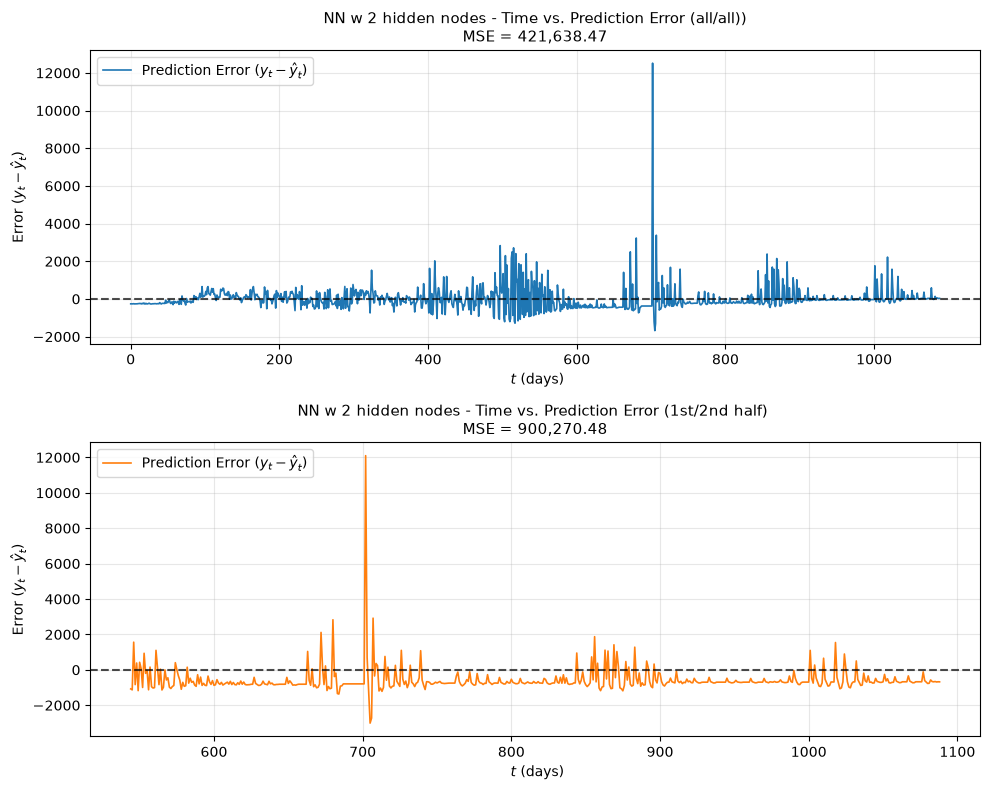

In [20]:
# create plot for all/all
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=False)

# Plot 2a
axes[0].plot(
    df_honduras.index,
    errors_nn1_all,
    color="tab:blue",
    linewidth=1.2,
    label=r"Prediction Error ($y_t - \hat{y}_t$)",
)
axes[0].axhline(0, color="black", linestyle="--", alpha=0.7)
axes[0].set_title(
    f"NN w 2 hidden nodes - Time vs. Prediction Error (all/all))\nMSE = {mse_nn1_all:,.2f}",
    fontsize=11,
)
axes[0].set_xlabel(r" $t$ (days)")
axes[0].set_ylabel(r"Error ($y_t - \hat{y}_t$)")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# create plot for first/second half
axes[1].plot(
    test_index,
    errors_nn1_half,
    color="tab:orange",
    linewidth=1.2,
    label=r"Prediction Error ($y_t - \hat{y}_t$)",
)
axes[1].axhline(0, color="black", linestyle="--", alpha=0.7)
axes[1].set_title(
    f"NN w 2 hidden nodes - Time vs. Prediction Error (1st/2nd half) \nMSE = {mse_nn1_half:,.2f}",
    fontsize=11,
)
axes[1].set_xlabel(r" $t$ (days)")
axes[1].set_ylabel(r"Error ($y_t - \hat{y}_t$)")
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Part 2: NN w 2 hidden layers, 2 noders per layer**

In [21]:
# all/all
nn2_all = MLPRegressor(
    hidden_layer_sizes=(2, 2),
    activation="relu",
    solver="lbfgs",
    max_iter=5000,
    random_state=42,
)
nn2_all.fit(X_all_scaled, y_all)

y_pred_nn2_all = nn2_all.predict(X_all_scaled)
errors_nn2_all = y_all - y_pred_nn2_all
mse_nn2_all = np.mean(errors_nn2_all**2)

print(f"NN w 2 hidden layers, 2 nodes per layer MSE: {mse_nn2_all:,.4f}")

NN w 2 hidden layers, 2 nodes per layer MSE: 27,433,223,388.5494


In [22]:
# first half/second half
nn2_half = MLPRegressor(
    hidden_layer_sizes=(2, 2),
    activation="relu",
    solver="lbfgs",
    max_iter=5000,
    random_state=42,
)
nn2_half.fit(X_train_scaled, y_train)

y_pred_nn2_half = nn2_half.predict(X_test_scaled)
errors_nn2_half = y_test - y_pred_nn2_half
mse_nn2_half = np.mean(errors_nn2_half**2)

print(f"NN w 2 hidden layers, 2 noder per layer (1st/2nd half) - MSE: {mse_nn2_half:,.4f}")

NN w 2 hidden layers, 2 noder per layer (1st/2nd half) - MSE: 18,976,627,755.8135


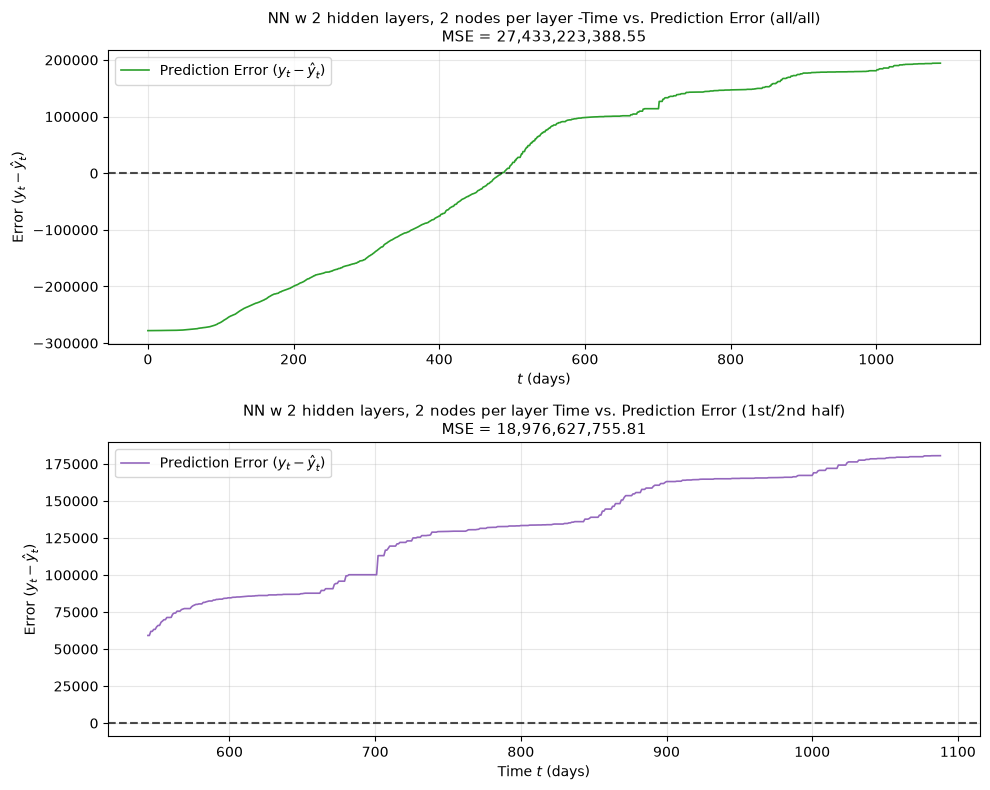

In [ ]:
# create plot for all/all
ig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=False)

# Plot 2a
axes[0].plot(
    df_honduras.index,
    errors_nn2_all,
    color="tab:green",
    linewidth=1.2,
    label=r"Prediction Error ($y_t - \hat{y}_t$)",
)
axes[0].axhline(0, color="black", linestyle="--", alpha=0.7)
axes[0].set_title(
    f"NN w 2 hidden layers, 2 nodes per layer -Time vs. Prediction Error (all/all)\nMSE = {mse_nn2_all:,.2f}",
    fontsize=11,
)
axes[0].set_xlabel(r"$t$ (days)")
axes[0].set_ylabel(r"Error ($y_t - \hat{y}_t$)")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# create plot for first half/second half
axes[1].plot(
    test_index,
    errors_nn2_half,
    color="tab:purple",
    linewidth=1.2,
    label=r"Prediction Error ($y_t - \hat{y}_t$)",
)
axes[1].axhline(0, color="black", linestyle="--", alpha=0.7)
axes[1].set_title(
    f"NN w 2 hidden layers, 2 nodes per layer Time vs. Prediction Error (1st/2nd half)\nMSE = {mse_nn2_half:,.2f}",
    fontsize=11,
)
axes[1].set_xlabel(r"$t$ (days)")
axes[1].set_ylabel(r"Error ($y_t - \hat{y}_t$)")
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()